# 01 - Exploratory Data Analysis: Heart Disease UCI (Cleveland)
Binary target: `num` > 0 -> heart disease present (1).

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

logging.basicConfig(level=logging.INFO)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
NUM = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CAT = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
raw = pd.read_csv(ROOT / "data" / "raw" / "heart.csv", na_values=["?"])
df = pd.read_csv(ROOT / "data" / "processed" / "heart_clean.csv")


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## 1. Dataset summary

In [2]:
print(df.shape)
df.describe().T.round(2)

(303, 14)


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


**Insight:** 303 patients, 13 predictors. Ages 29-77 (mean ~54); `oldpeak` and `chol` are right-skewed, hinting at outliers worth robust scaling/checking.

## 2. Missing values (raw data)

In [3]:
miss = pd.DataFrame({"missing": raw.isna().sum(),
                     "pct": (raw.isna().mean() * 100).round(2)})
miss[miss.missing > 0]

,missing,pct
ca,4,1.32
thal,2,0.66


**Insight:** Only `ca` (4) and `thal` (2) have missing values in the raw file (<2% of rows), so mode imputation is safe and loses no rows.

## 3. Histograms of numeric features

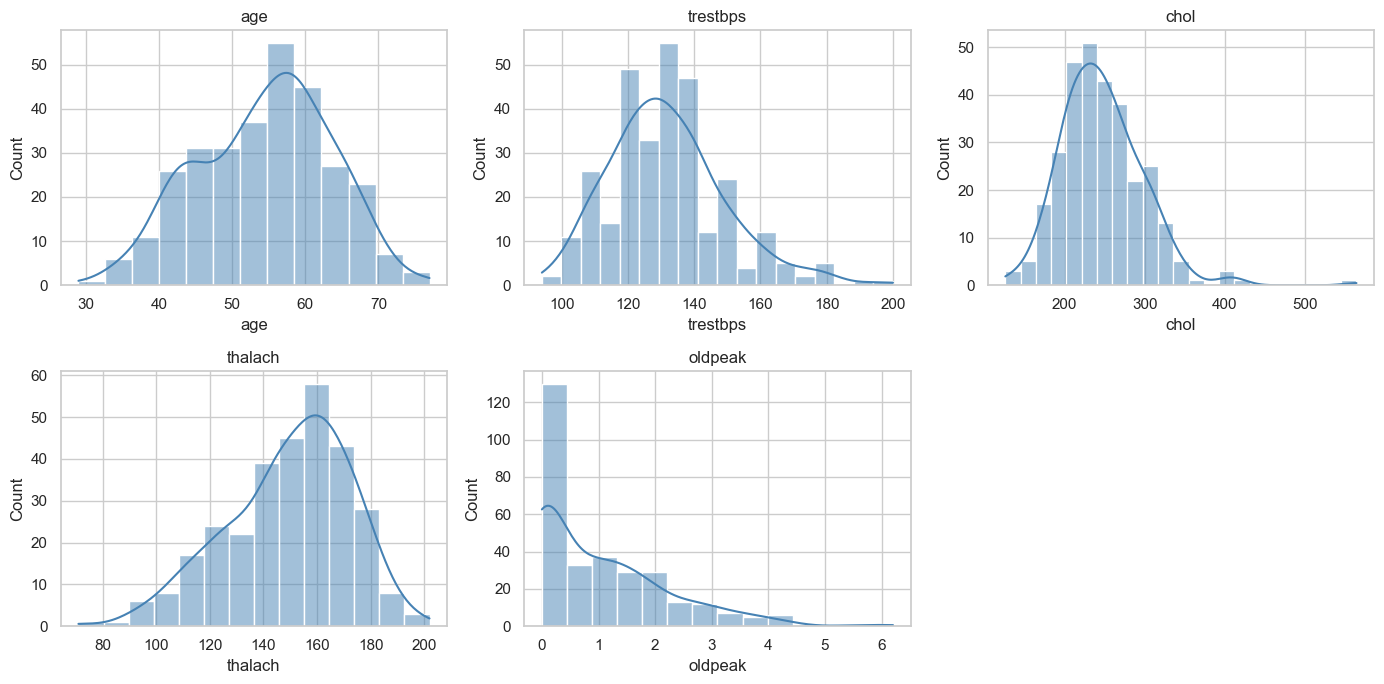

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUM):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
save("hist_numeric.png")

**Insight:** `chol` and `oldpeak` are right-skewed (skew ~1.1 and ~1.3) while `thalach` leans left; `age` and `trestbps` are roughly bell-shaped. Scaling is needed for linear models.

## 4. Categorical features vs target

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


...

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


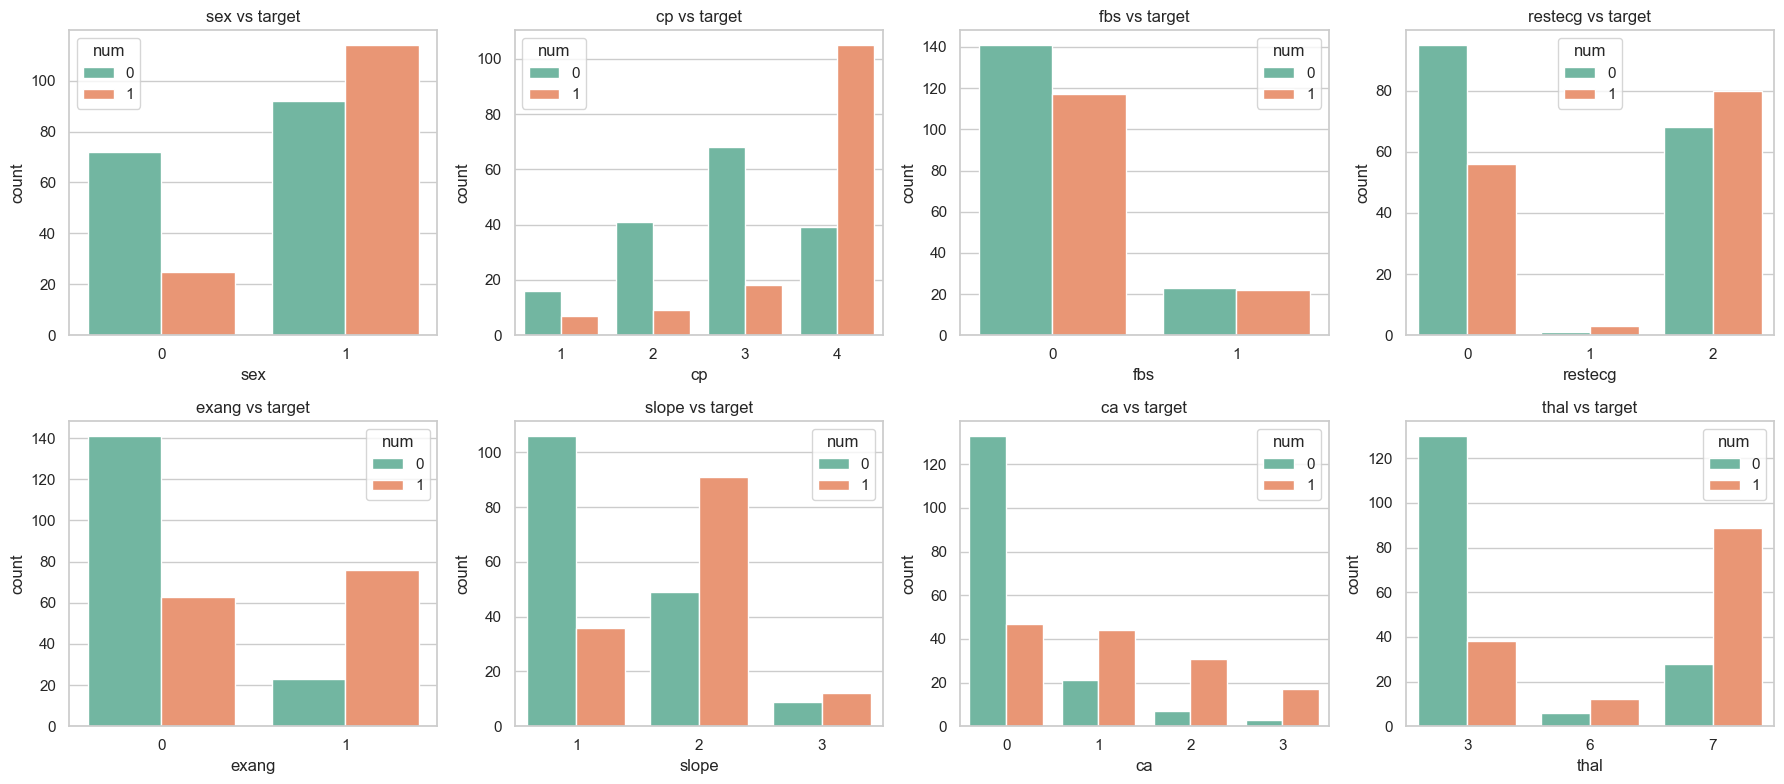

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), CAT):
    sns.countplot(data=df, x=col, hue="num", ax=ax, palette="Set2")
    ax.set_title(f"{col} vs target")
save("countplots_categorical.png")

**Insight:** Disease prevalence is ~73% for asymptomatic chest pain (`cp`=4) vs ~18-30% for other types, ~77% with exercise angina, and rises steadily with `ca` (26% at 0 vessels -> 85% at 3).

## 5. Correlation heatmap

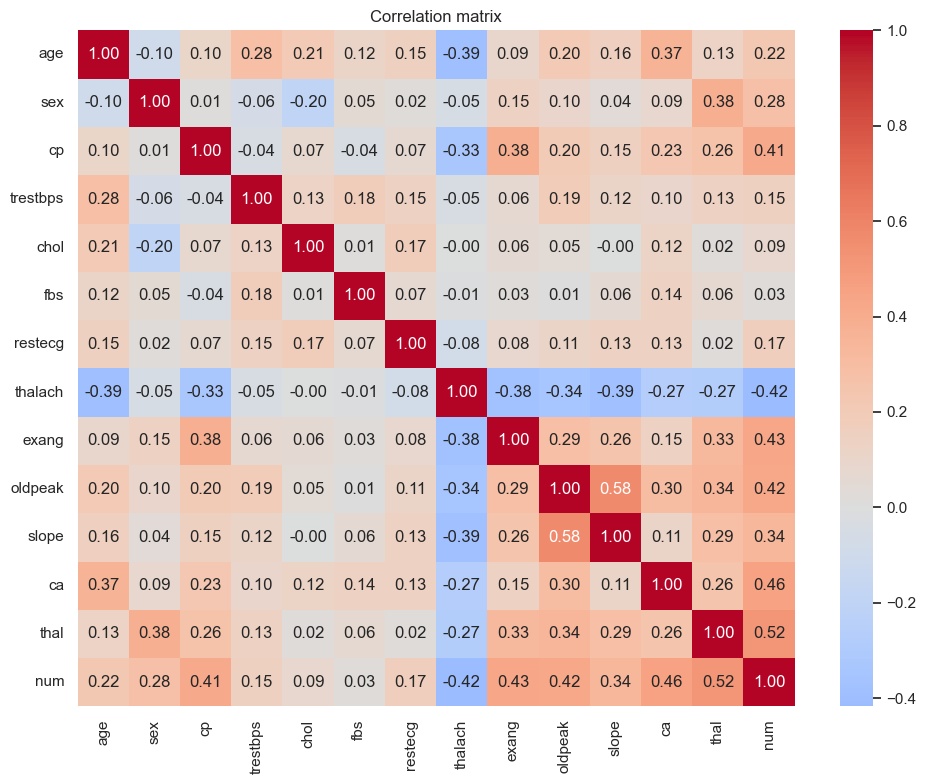

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
save("correlation_heatmap.png")

**Insight:** Strongest correlates of disease are `thal` (0.52), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42), `cp` (0.41) and `thalach` (-0.42). No pair of predictors is highly collinear, so all can be kept.

## 6. Class balance

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


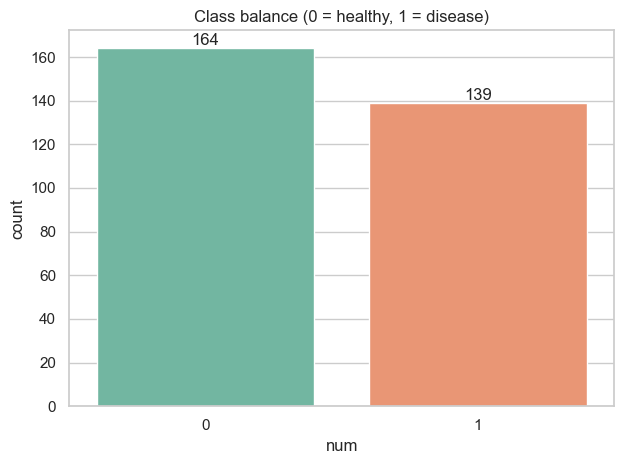

num
0    0.541
1    0.459
Name: proportion, dtype: float64

In [7]:
ax = sns.countplot(data=df, x="num", hue="num", palette="Set2", legend=False)
for c in ax.containers:
    ax.bar_label(c)
plt.title("Class balance (0 = healthy, 1 = disease)")
save("class_balance.png")
df.num.value_counts(normalize=True).round(3)

**Insight:** 164 healthy vs 139 diseased (54% / 46%). Classes are nearly balanced, so accuracy is meaningful, though we optimise ROC-AUC and watch recall for screening.

## 7. Boxplots by target

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


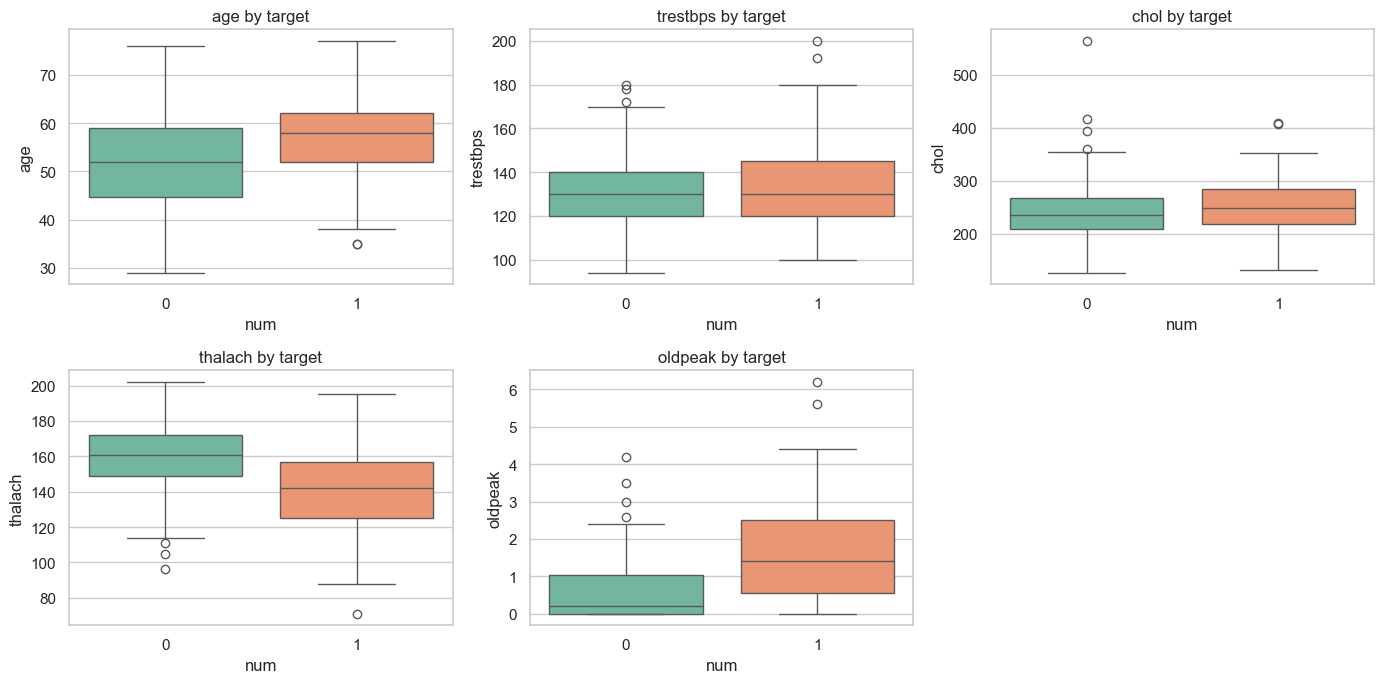

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUM):
    sns.boxplot(data=df, x="num", y=col, hue="num", ax=ax, palette="Set2", legend=False)
    ax.set_title(f"{col} by target")
axes.ravel()[-1].axis("off")
save("boxplots_by_target.png")

**Insight:** Diseased patients have markedly lower max heart rate (`thalach` mean 139 vs 158) and higher `oldpeak` (1.6 vs 0.6); `chol` and `trestbps` overlap heavily and are weaker signals.